# **Day 97: Project - Kolkata Metro Route Finder (Graphs)**

A metro network is a **graph**.
- **Nodes** (or vertices) = stations
- **Edges** = the tracks between two stations

Finding a route = **searching the graph**. The same idea is used in Google Maps, and in GIS **network analysis** (shortest path, service areas, nearest hospital).

**Note:** The network below is **simplified** and partly written from memory. Some lines are still being built, and some station names may be slightly different. The main aim is to learn the algorithms.

In [1]:
LINES = {
    "Blue": ["Dakshineswar", "Baranagar", "Noapara", "Dum Dum", "Belgachia", "Shyambazar", "Shobhabazar",
             "Girish Park", "MG Road", "Central", "Chandni Chowk", "Esplanade", "Park Street", "Maidan",
             "Rabindra Sadan", "Netaji Bhavan", "Jatin Das Park", "Kalighat", "Rabindra Sarobar",
             "Mahanayak Uttam Kumar", "Netaji", "Masterda Surya Sen", "Gitanjali", "Kavi Nazrul",
             "Shahid Khudiram", "Kavi Subhash"],
    "Green": ["Howrah Maidan", "Howrah", "Mahakaran", "Esplanade", "Sealdah", "Phoolbagan",
              "Salt Lake Stadium", "Bengal Chemical", "City Centre", "Central Park", "Karunamoyee",
              "Salt Lake Sector V"],
    "Purple": ["Joka", "Thakurpukur", "Sakher Bazar", "Behala Chowrasta", "Behala Bazar", "Taratala", "Majerhat"],
    "Orange": ["Kavi Subhash", "Satyajit Ray", "Jyotirindra Nandi", "Kavi Sukanta", "Hemanta Mukhopadhyay", "Beleghata"],
    "Yellow": ["Noapara", "Dum Dum Cantonment", "Jessore Road", "Jai Hind Bimanbandar"],
}

## **Step 1: Build the Graph**
We store the graph as an **adjacency list**: a dictionary where each station has a set of its **neighbour** stations.

In [2]:
from collections import defaultdict, deque

graph = defaultdict(set)            # station -> neighbouring stations
station_lines = defaultdict(set)    # station -> lines it belongs to

for line, stops in LINES.items():
    for a, b in zip(stops, stops[1:]):
        graph[a].add(b)
        graph[b].add(a)
    for s in stops:
        station_lines[s].add(line)

interchanges = {s: sorted(l) for s, l in station_lines.items() if len(l) > 1}
print(len(graph), "stations")
print(sum(len(n) for n in graph.values()) // 2, "track links")
print("Interchange stations:", interchanges)

52 stations
50 track links
Interchange stations: {'Noapara': ['Blue', 'Yellow'], 'Esplanade': ['Blue', 'Green'], 'Kavi Subhash': ['Blue', 'Orange']}


## **Step 2: BFS - The Route with the Fewest Stations**
**BFS (Breadth First Search)** explores the graph **level by level**: first all stations 1 stop away, then all stations 2 stops away, and so on. So the first time it reaches the destination, it has used the **fewest stops**.

**Real-life example:** Throwing a stone in a pond. The ripples spread out evenly in all directions.

In [3]:
def bfs_route(start, goal):
    previous = {start: None}
    queue = deque([start])
    while queue:
        current = queue.popleft()
        if current == goal:
            break
        for nxt in sorted(graph[current]):
            if nxt not in previous:
                previous[nxt] = current
                queue.append(nxt)
    if goal not in previous:
        return None
    path = []
    while goal is not None:            # Walk backwards from the goal to the start
        path.append(goal)
        goal = previous[goal]
    return path[::-1]

route = bfs_route("Howrah", "Kalighat")
print(len(route) - 1, "stops:", " -> ".join(route))

8 stops: Howrah -> Mahakaran -> Esplanade -> Park Street -> Maidan -> Rabindra Sadan -> Netaji Bhavan -> Jatin Das Park -> Kalighat


## **Step 3: Dijkstra's Algorithm - The Fastest Route**
The route with the fewest stations is not always the **fastest**, because **changing lines** takes time (walking, waiting). Let us say:
- Riding to the next station takes **2.5 minutes**
- Changing to another line takes **7 minutes**

**Dijkstra's algorithm** finds the path with the **lowest total cost** (time). It always continues from the **cheapest** place found so far, using a **priority queue** (`heapq`).

To count line changes, our "position" is not just a station but a **(station, line)** pair.

In [4]:
import heapq

RIDE, CHANGE = 2.5, 7.0

def next_stations(station, line):
    stops = LINES[line]
    i = stops.index(station)
    return [stops[j] for j in (i - 1, i + 1) if 0 <= j < len(stops)]

def fastest_route(start, goal):
    queue = [(0.0, start, line, [(start, line)]) for line in station_lines[start]]
    heapq.heapify(queue)
    done = set()
    while queue:
        time_so_far, station, line, path = heapq.heappop(queue)
        if (station, line) in done:
            continue
        done.add((station, line))
        if station == goal:
            return time_so_far, path
        for nxt in next_stations(station, line):
            heapq.heappush(queue, (time_so_far + RIDE, nxt, line, path + [(nxt, line)]))
        for other in station_lines[station] - {line}:
            heapq.heappush(queue, (time_so_far + CHANGE, station, other, path + [(station, other)]))
    return None

def show_route(start, goal):
    result = fastest_route(start, goal)
    if result is None:
        print(f"No route from {start} to {goal}\n")
        return
    minutes, path = result
    print(f"{start} -> {goal}: about {minutes:.0f} minutes")
    legs = []
    for station, line in path:
        if not legs or legs[-1][0] != line:
            legs.append([line, station, station, 0])
        else:
            legs[-1][2] = station
            legs[-1][3] += 1
    for line, a, b, n in legs:
        if n:
            print(f"   {line:<7} Line: {a} -> {b} ({n} stops)")
    print()

show_route("Howrah", "Kalighat")
show_route("Salt Lake Sector V", "Jai Hind Bimanbandar")
show_route("Dakshineswar", "Beleghata")
show_route("Joka", "Esplanade")

Howrah -> Kalighat: about 27 minutes
   Green   Line: Howrah -> Esplanade (2 stops)
   Blue    Line: Esplanade -> Kalighat (6 stops)

Salt Lake Sector V -> Jai Hind Bimanbandar: about 64 minutes
   Green   Line: Salt Lake Sector V -> Esplanade (8 stops)
   Blue    Line: Esplanade -> Noapara (9 stops)
   Yellow  Line: Noapara -> Jai Hind Bimanbandar (3 stops)

Dakshineswar -> Beleghata: about 82 minutes
   Blue    Line: Dakshineswar -> Kavi Subhash (25 stops)
   Orange  Line: Kavi Subhash -> Beleghata (5 stops)

No route from Joka to Esplanade



Let us understand the code above:
- `heapq.heappop(queue)` always gives the entry with the **smallest time**. That is the key idea of Dijkstra.
- From each (station, line), we can either **ride** to the next station on the same line (+2.5 min), or **change line** at an interchange (+7 min).
- `done` remembers the (station, line) pairs already finished, so we never process them twice.
- **Joka to Esplanade** has no route in our data, because the Purple Line is not connected to the other lines in this simplified network. The code handles this properly.

## **Step 4: Connected Parts of the Network**
A **connected component** is a group of stations where you can travel between any two of them.

In [5]:
def reachable_from(start):
    seen = {start}
    queue = deque([start])
    while queue:
        for n in graph[queue.popleft()]:
            if n not in seen:
                seen.add(n)
                queue.append(n)
    return seen

components = []
remaining = set(graph)
while remaining:
    part = reachable_from(next(iter(sorted(remaining))))
    components.append(part)
    remaining -= part

for part in components:
    print(len(part), "stations, for example:", sorted(part)[:3])

45 stations, for example: ['Baranagar', 'Beleghata', 'Belgachia']
7 stations, for example: ['Behala Bazar', 'Behala Chowrasta', 'Joka']


## **Step 5: Drawing the Network**

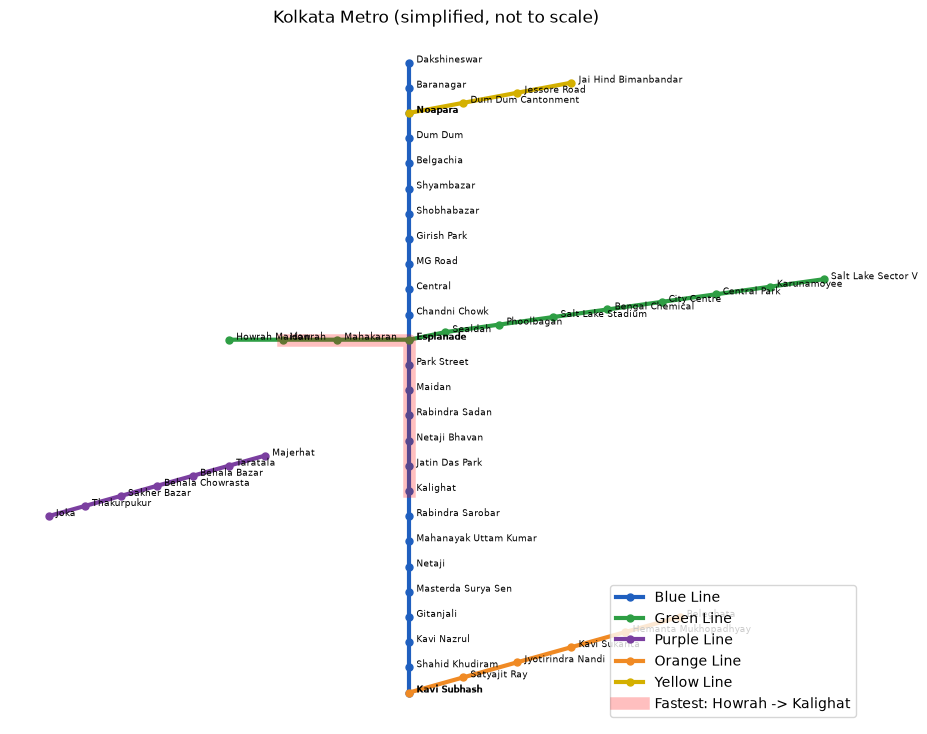

In [6]:
import matplotlib.pyplot as plt

colours = {"Blue": "#1f5fbf", "Green": "#2e9e44", "Purple": "#7b3fa0", "Orange": "#f08a24", "Yellow": "#d4b000"}
pos = {}                                        # Simple made-up positions (not to scale)
for i, s in enumerate(LINES["Blue"]):
    pos[s] = (0, -i)
for i, s in enumerate(LINES["Green"]):
    pos.setdefault(s, (-3 + i * 0.9, pos["Esplanade"][1] + (0 if i <= 3 else 0.3 * (i - 3))))
for i, s in enumerate(LINES["Orange"]):
    pos.setdefault(s, (i * 0.9, pos["Kavi Subhash"][1] + i * 0.6))
for i, s in enumerate(LINES["Yellow"]):
    pos.setdefault(s, (i * 0.9, pos["Noapara"][1] + i * 0.4))
for i, s in enumerate(LINES["Purple"]):
    pos.setdefault(s, (-6 + i * 0.6, -18 + i * 0.4))

fig, ax = plt.subplots(figsize=(11, 9))
for line, stops in LINES.items():
    xs, ys = zip(*(pos[s] for s in stops))
    ax.plot(xs, ys, "-o", color=colours[line], lw=3, ms=5, label=f"{line} Line")
for s, (x, y) in pos.items():
    ax.text(x + 0.12, y, s, fontsize=6.5, weight="bold" if s in interchanges else "normal")

best = [s for s, _ in fastest_route("Howrah", "Kalighat")[1]]
rx, ry = zip(*(pos[s] for s in best))
ax.plot(rx, ry, color="red", lw=9, alpha=0.25, label="Fastest: Howrah -> Kalighat")
ax.legend(loc="lower right")
ax.set_axis_off()
ax.set_title("Kolkata Metro (simplified, not to scale)")
plt.show()

## **What We Learned**
- A network can be stored as a **graph** (adjacency list).
- **BFS** finds the route with the fewest stops.
- **Dijkstra** finds the route with the lowest total cost (time, distance, money).
- The same ideas are used in GIS **network analysis**, for example finding the nearest hospital by road, or the fastest route for an ambulance. (The Python library **NetworkX**, and the **OSMnx** library for real road networks, do all of this.)